<a href="https://colab.research.google.com/github/SashaVeremchuk/ML_ITMO/blob/main/Kluster_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering Challenge

Индивидуальная лабораторная работа по кластерному анализу.


## Данные участника

ФИО: Веремчук Александра Олеговна  
Email: veremchuk.alexandra@gmail.com  
ВУЗ: ИТМО  


## Загрузка открытых данных

`train.csv` включает 24 независимых набора данных (dataset_id).  
Итоговый объём:  
* всего объектов после расширения: 29 324;  
* открытый train: 23 461 объектов;  
* скрытый test: 5 863 объектов.  

Столбцы:
* id;
* dataset_id;
* x1, x2, ..., xp.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="Set2")

In [ ]:
train = pd.read_csv('train.csv')
train.head()

,id,dataset_id,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,ds12_0036,ds12,-5.458615,-3.558217,5.827375,-2.092496,-3.683893,4.888487,-1.603157,-4.435367,NaN,NaN,NaN,NaN,NaN,NaN
1,ds03_0796,ds03,-292.185190,297.524405,-291.036668,277.591509,34.831800,249.916693,-125.336260,271.259395,-87.427939,NaN,NaN,NaN,NaN,NaN
2,ds19_aug_00247,ds19,-0.834503,0.500650,0.340247,-0.063154,-0.719844,-0.013748,-0.715986,-1.076471,NaN,NaN,NaN,NaN,NaN,NaN
3,ds03_aug_00328,ds03,-360.217653,365.890241,-358.804030,342.245846,42.956813,306.995541,-153.467907,332.927240,-266.570995,NaN,NaN,NaN,NaN,NaN
4,ds23_0799,ds23,0.956654,0.098221,-0.788004,-0.061757,0.036601,-0.338004,0.676962,0.103862,1.197653,-0.217335,NaN,NaN,NaN,NaN


## EDA  
Удали хвостовые столбцы, которые полностью состоят из NaN.  
Посмотрим на статистику по признакам.

In [ ]:
feature_cols = [col for col in train.columns if col.startswith("x")]

# Словарь для хранения очищенных датасетов
datasets = {}
summary_rows = []

for ds_id, group in train.groupby("dataset_id"):
    X_ds = group[feature_cols].dropna(axis=1, how="all")
    datasets[ds_id] = X_ds

    # Сбор статистики по признакам
    stds = X_ds.std()
    summary_rows.append({
        "dataset_id": ds_id,
        "n_samples": len(X_ds),
        "n_features": X_ds.shape[1],
        "missing_vals": X_ds.isna().sum().sum(),
        "min_val": round(X_ds.min().min(), 2),
        "max_val": round(X_ds.max().max(), 2)
    })

summary_df = pd.DataFrame(summary_rows).sort_values("dataset_id").reset_index(drop=True)
display(summary_df)

,dataset_id,n_samples,n_features,missing_vals,min_val,max_val
0,ds00,960,9,0,-7.14,7.59
1,ds01,936,6,0,-146.83,168.26
2,ds02,1010,10,0,-8.14,7.74
3,ds03,960,9,0,-535.01,479.65
4,ds04,936,9,0,-20.54,28.56
5,ds05,1008,11,0,-7.51,9.10
6,ds06,972,10,0,-8.68,7.32
7,ds07,960,10,0,-7.44,7.00
8,ds08,1032,13,0,-25.36,25.57
9,ds09,1056,12,0,-18.84,20.20


**Вывод:**  
В наборе ds20 есть 3 пропущенных значения. Перед визуализацией заполним эти значения медианным значением и стандартизуем данные.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

scaled_datasets = {}

for ds_id, X_df in datasets.items():
    X_imp = SimpleImputer(strategy="median").fit_transform(X_df)
    X_std = StandardScaler().fit_transform(X_imp)
    scaled_datasets[ds_id] = X_std

## Визуализация данных
Используем методы снижения размерности: PCA и t-SNE.   
Линейный PCA отражает глобальную геометрию данных - реальные пропорции облаков, их вытянутость, выбросы и линейную разделимость, но может "склеивать" сложные фигуры.    
Нелинейный t-SNE, напротив, сохраняет локальных соседей и позволяет увидеть скрытые нелинейные структуры (кольца, дуги, плотностные сгустки), компенсируя слепые зоны PCA и защищая от ложных выводов при выборе алгоритма.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

def plot_geometry(data_dict, method="pca", random_state=42):
  """ Функция построения сетки графиков (PCA и t-SNE)"""

  sorted_ids = sorted(data_dict.keys())
  cols = 4
  rows = 6
  fig, axes = plt.subplots(rows, cols, figsize=(20, 26))
  axes = axes.flatten()

  for idx, ds_id in enumerate(sorted_ids):
      ax = axes[idx]
      X = data_dict[ds_id]

      if method == "pca":
          proj = PCA(n_components=2, random_state=random_state).fit_transform(X)
          title_method = "PCA"
      else:
          proj = TSNE(n_components=2, perplexity=30, random_state=random_state).fit_transform(X)
          title_method = "t-SNE"

      ax.scatter(proj[:, 0], proj[:, 1], s=12, alpha=0.7, c="royalblue", edgecolors="none")
      ax.set_title(f"{ds_id} ({title_method}, d={X.shape[1]})", fontsize=11, fontweight="bold")
      ax.set_xticks([])
      ax.set_yticks([])

  plt.tight_layout()
  plt.show()

### Графики PCA

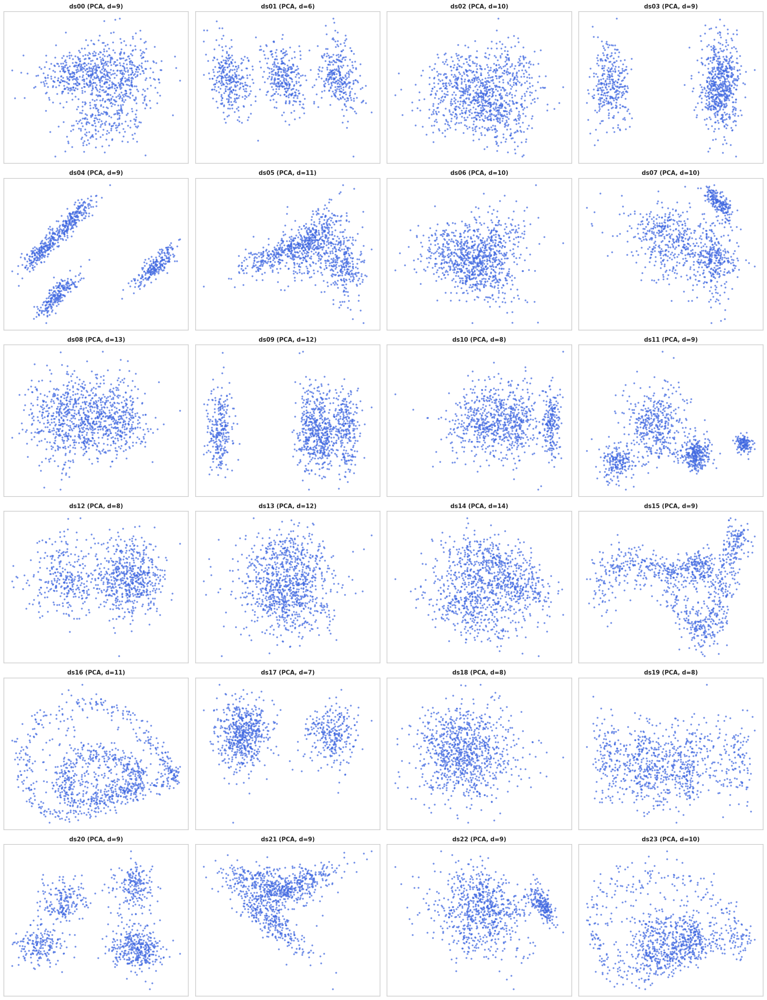

In [ ]:
plot_geometry(scaled_datasets, method="pca")

### Графики t-SNE

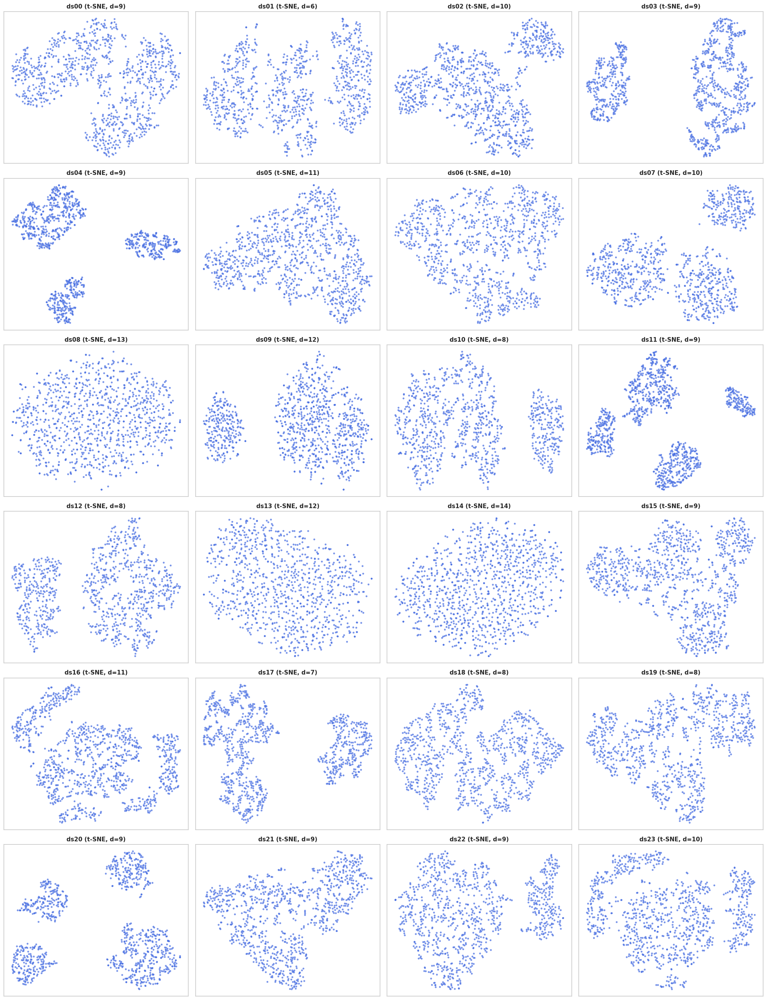

In [ ]:
plot_geometry(scaled_datasets, method="tsne")

# Моя проверка


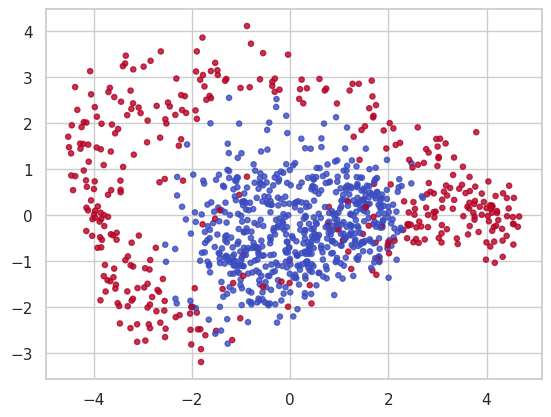

In [ ]:
radii = np.linalg.norm(X_raw, axis=1).reshape(-1, 1)
labels = KMeans(n_clusters=2, n_init=20, random_state=42).fit_predict(radii)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="coolwarm", s=14, alpha=0.8)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

ds_key = "ds23"
X_df = pd.DataFrame(scaled_datasets[ds_key])
X_all = X_df.values

print(f"=== 1. ДИАГНОСТИКА ДАННЫХ ({ds_key}, строк: {X_df.shape}, признаков: {X_df.shape}) ===")
pca = PCA().fit(X_all)
print("Доля дисперсии PCA:", [f"PC{i}:{r:.1%}" for i, r in enumerate(pca.explained_variance_ratio_, 1) if r > 0.001])

# Оценка значимости признаков на базе GMM full (k=2) (ядро + оболочка)
base_labels = GaussianMixture(n_components=2, covariance_type="full", n_init=10, random_state=42).fit_predict(X_all)
f_vals, p_vals = f_classif(X_all, base_labels)

importance = pd.DataFrame({
    "Признак": X_df.columns,
    "F-статистика": np.round(f_vals, 2),
    "p-value": np.round(p_vals, 4),
    "Статус": np.where(p_vals < 0.05, "Значимый", "Шум (удалить)")
}).sort_values(by="F-статистика", ascending=False)

print("\n=== 2. ОЦЕНКА ВКЛАДА ПРИЗНАКОВ (GMM full k=2) ===")
display(importance)

# Примечание: для вложенных концентрических облаков F-тест по средним может быть низким,
# поэтому проверяем и дисперсию/разброс признаков, а также тестируем на всех и очищенных признаках
good_cols = importance[importance["p-value"] < 0.05]["Признак"].tolist()
sets = {f"Все признаки (d={X_df.shape[1]})": X_all}
if 2 <= len(good_cols) < X_df.shape[1]:
    sets[f"После F-теста (d={len(good_cols)})"] = X_df[good_cols].values

print("\n=== 3. СРАВНЕНИЕ GMM FULL И РАДИУСА R ДЛЯ DS23 ===")
for name_set, X_curr in sets.items():
    print(f"--- {name_set} ---")
    for k in [2, 3, 4]:
        gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=10, random_state=42)
        lbl = gmm.fit_predict(X_curr)
        sizes = list(pd.Series(lbl).value_counts().sort_index().values)
        print(f"GMM full (k={k})      | Размеры: {str(sizes):22} | BIC: {gmm.bic(X_curr):8.1f} | DB: {davies_bouldin_score(X_curr, lbl):.4f}")

    # Проверяем радиус R по первым главным компонентам PCA(3) и по всем признакам
    R_all = np.linalg.norm(X_curr, axis=1).reshape(-1, 1)
    gmm_r = GaussianMixture(n_components=2, n_init=10, random_state=42)
    lbl_r = gmm_r.fit_predict(R_all)
    sizes_r = list(pd.Series(lbl_r).value_counts().sort_index().values)
    print(f"GMM(k=2) по R(all)  | Размеры: {str(sizes_r):22} | Sil(R): {silhouette_score(R_all, lbl_r):.4f}")


=== 1. ДИАГНОСТИКА ДАННЫХ (ds23, строк: (1008, 10), признаков: (1008, 10)) ===
Доля дисперсии PCA: ['PC1:48.9%', 'PC2:16.7%', 'PC3:10.2%', 'PC4:9.6%', 'PC5:7.2%', 'PC6:4.4%', 'PC7:1.7%', 'PC8:0.5%', 'PC9:0.3%', 'PC10:0.3%']

=== 2. ОЦЕНКА ВКЛАДА ПРИЗНАКОВ (GMM full k=2) ===


,Признак,F-статистика,p-value,Статус
1,1,410.86,0.0000,Значимый
5,5,340.45,0.0000,Значимый
8,8,136.94,0.0000,Значимый
9,9,111.55,0.0000,Значимый
0,0,29.50,0.0000,Значимый
6,6,17.30,0.0000,Значимый
3,3,7.05,0.0081,Значимый
2,2,5.74,0.0168,Значимый
4,4,5.47,0.0195,Значимый
7,7,1.57,0.2107,Шум (удалить)



=== 3. СРАВНЕНИЕ GMM FULL И РАДИУСА R ДЛЯ DS23 ===
--- Все признаки (d=10) ---
GMM full (k=2)      | Размеры: [np.int64(504), np.int64(504)] | BIC:  17075.0 | DB: 3.0723
GMM full (k=3)      | Размеры: [np.int64(608), np.int64(213), np.int64(187)] | BIC:  17076.7 | DB: 1.6146
GMM full (k=4)      | Размеры: [np.int64(194), np.int64(528), np.int64(131), np.int64(155)] | BIC:  16731.0 | DB: 1.6649
GMM(k=2) по R(all)  | Размеры: [np.int64(626), np.int64(382)] | Sil(R): 0.6387
--- После F-теста (d=9) ---
GMM full (k=2)      | Размеры: [np.int64(541), np.int64(467)] | BIC:  15769.2 | DB: 2.7217
GMM full (k=3)      | Размеры: [np.int64(256), np.int64(554), np.int64(198)] | BIC:  15708.2 | DB: 1.9248
GMM full (k=4)      | Размеры: [np.int64(177), np.int64(205), np.int64(510), np.int64(116)] | BIC:  15541.6 | DB: 1.8493
GMM(k=2) по R(all)  | Размеры: [np.int64(625), np.int64(383)] | Sil(R): 0.6336


GMM (k=2) по центрированному R    -> {0: np.int64(762), 1: np.int64(246)} | Sil(R): 0.6125
KMeans (k=2) по центрированному R -> {0: np.int64(689), 1: np.int64(319)} | Sil(R): 0.5943


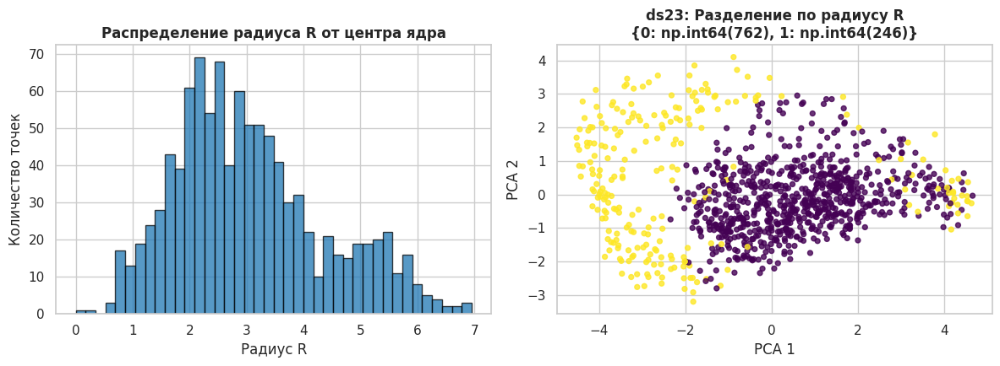

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Удаляем шумовой столбец 7
X_clean = pd.DataFrame(scaled_datasets["ds23"]).drop(columns=[7]).values

# 2. Берём первые 6 компонент PCA (убираем мелкий хвост PC7-PC9)
X_pca = PCA(n_components=6, random_state=42).fit_transform(X_clean)

# 3. Находим центр плотного внутреннего ядра (точка с минимальным расстоянием до 30 ближайших соседей)
nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
distances, _ = nn.kneighbors(X_pca)
core_idx = np.argmin(distances.mean(axis=1))
core_center = X_pca[core_idx]

# 4. Считаем радиус R относительно центра плотного ядра
R_centered = np.linalg.norm(X_pca - core_center, axis=1).reshape(-1, 1)

# 5. Кластеризуем по радиусу R (сравниваем GMM и KMeans)
gmm_r = GaussianMixture(n_components=2, n_init=10, random_state=42)
lbl_gmm = gmm_r.fit_predict(R_centered)

km_r = KMeans(n_clusters=2, n_init=20, random_state=42)
lbl_km = km_r.fit_predict(R_centered)

print("GMM (k=2) по центрированному R    ->", dict(pd.Series(lbl_gmm).value_counts().sort_index()), f"| Sil(R): {silhouette_score(R_centered, lbl_gmm):.4f}")
print("KMeans (k=2) по центрированному R ->", dict(pd.Series(lbl_km).value_counts().sort_index()), f"| Sil(R): {silhouette_score(R_centered, lbl_km):.4f}")

# 6. Визуальная проверка гистограммы радиусов и разделения на PCA
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(R_centered, bins=40, color="#1f77b4", edgecolor="black", alpha=0.75)
axes[0].set_title("Распределение радиуса R от центра ядра", fontweight="bold")
axes[0].set_xlabel("Радиус R")
axes[0].set_ylabel("Количество точек")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=lbl_gmm, cmap="viridis", s=18, alpha=0.8)
axes[1].set_title(f"ds23: Разделение по радиусу R\n{dict(pd.Series(lbl_gmm).value_counts().sort_index())}", fontweight="bold")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")

plt.tight_layout()
plt.show()


In [ ]:
X_clean6 = pd.DataFrame(scaled_datasets["ds19"]).drop(columns=).values

for name, m in [
    ("KMeans (k=3)", KMeans(n_clusters=3, n_init=20, random_state=42)),
    ("GMM full (k=3)", GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)),
    ("GMM tied (k=3)", GaussianMixture(n_components=3, covariance_type="tied", n_init=10, random_state=42)),
]:
    lbl = m.fit_predict(X_clean6)
    sizes = list(pd.Series(lbl).value_counts().sort_index().values)
    bic = f"{m.bic(X_clean6):.1f}" if hasattr(m, "bic") else "-"
    print(f"{name:15} | Размеры: {str(sizes):24} | BIC: {bic:8} | Sil: {silhouette_score(X_clean6, lbl):.4f} | DB: {davies_bouldin_score(X_clean6, lbl):.4f}")


SyntaxError: expected argument value expression (623942474.py, line 1)

Радиус по всем 9 призм. | KMeans -> Размеры: {0: np.int64(444), 1: np.int64(612)} | Sil(R): 0.6621
Радиус по всем 9 призм. | GMM    -> Размеры: {0: np.int64(413), 1: np.int64(643)} | Sil(R): 0.6644

Радиус по PCA(2)        | KMeans -> Размеры: {0: np.int64(390), 1: np.int64(666)} | Sil(R): 0.6764
Радиус по PCA(2)        | GMM    -> Размеры: {0: np.int64(694), 1: np.int64(362)} | Sil(R): 0.6760



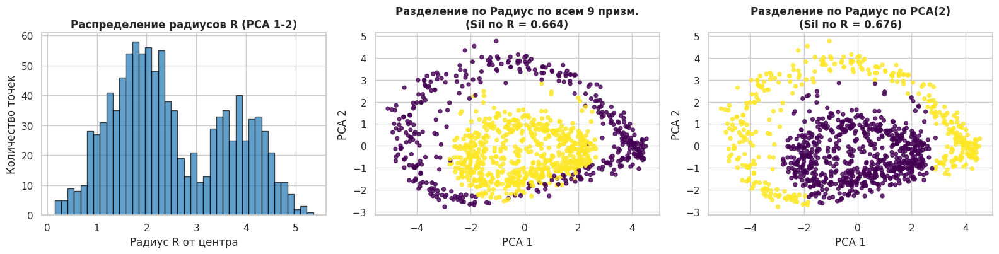

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

X_df = pd.DataFrame(scaled_datasets["ds16"])

# 1. Удаляем шумовые столбцы 3 и 5 (оставляем 9 чистых признаков)
X_clean = X_df.drop(columns=[3, 5]).values

# 2. Считаем радиус (расстояние от центра координат) для каждой точки
radii = np.linalg.norm(X_clean, axis=1).reshape(-1, 1)

# Радиус по первым 2 главным компонентам PCA (где лежит плоскость кольца)
X_pca3 = PCA(n_components=3, random_state=42).fit_transform(X_clean)
radii_pca2 = np.linalg.norm(X_pca3[:, :2], axis=1).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# График 1: Гистограмма радиусов
axes[0].hist(radii_pca2, bins=40, color="#1f77b4", edgecolor="black", alpha=0.7)
axes[0].set_title("Распределение радиусов R (PCA 1-2)", fontweight="bold")
axes[0].set_xlabel("Радиус R от центра")
axes[0].set_ylabel("Количество точек")

# Проверяем KMeans(k=2) и GMM(k=2) на радиусе R
for idx, (name, R_feat) in enumerate([("Радиус по всем 9 призм.", radii), ("Радиус по PCA(2)", radii_pca2)], 1):
    km_lbl = KMeans(n_clusters=2, n_init=20, random_state=42).fit_predict(R_feat)
    gmm_lbl = GaussianMixture(n_components=2, n_init=10, random_state=42).fit_predict(R_feat)

    sil_km = silhouette_score(R_feat, km_lbl)
    sil_gmm = silhouette_score(R_feat, gmm_lbl)

    print(f"{name:23} | KMeans -> Размеры: {dict(pd.Series(km_lbl).value_counts().sort_index())} | Sil(R): {sil_km:.4f}")
    print(f"{name:23} | GMM    -> Размеры: {dict(pd.Series(gmm_lbl).value_counts().sort_index())} | Sil(R): {sil_gmm:.4f}\n")

    axes[idx].scatter(X_pca3[:, 0], X_pca3[:, 1], c=gmm_lbl, cmap="viridis", s=18, alpha=0.8)
    axes[idx].set_title(f"Разделение по {name}\n(Sil по R = {sil_gmm:.3f})", fontweight="bold")
    axes[idx].set_xlabel("PCA 1")
    axes[idx].set_ylabel("PCA 2")

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Оставляем только 6 сильных признаков (убираем шум 2, 4 и слабый 3)
X_clean6 = pd.DataFrame(scaled_datasets["ds15"])[[6, 1, 0, 7, 8, 5]].values

for k in [2, 3, 4]:
    m = GaussianMixture(n_components=k, covariance_type="full", n_init=10, random_state=42)
    lbl = m.fit_predict(X_clean6)
    sizes = list(pd.Series(lbl).value_counts().sort_index().values)
    print(f"GMM full (k={k}) | Размеры: {str(sizes):26} | BIC: {m.bic(X_clean6):8.1f} | Sil: {silhouette_score(X_clean6, lbl):.4f} | CH: {calinski_harabasz_score(X_clean6, lbl):.2f} | DB: {davies_bouldin_score(X_clean6, lbl):.4f}")


GMM full (k=2) | Размеры: [np.int64(615), np.int64(369)] | BIC:   8718.7 | Sil: 0.3470 | CH: 595.30 | DB: 1.1557
GMM full (k=3) | Размеры: [np.int64(306), np.int64(374), np.int64(304)] | BIC:   8307.8 | Sil: 0.3727 | CH: 715.56 | DB: 0.9788
GMM full (k=4) | Размеры: [np.int64(235), np.int64(283), np.int64(245), np.int64(221)] | BIC:   8038.7 | Sil: 0.3796 | CH: 807.16 | DB: 0.9214


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

X_df = pd.DataFrame(scaled_datasets["ds14"])

# Оставляем 8 сильных признаков (убираем шум 13 и слабые 3, 4, 8, 6, 5)
X_top8 = X_df[[0, 12, 9, 2, 1, 11, 7, 10]].values
X_pca3 = PCA(n_components=3, random_state=42).fit_transform(X_top8)

for set_name, X_v in [("Топ-8 признаков (d=8)", X_top8), ("Топ-8 + PCA(3)", X_pca3)]:
    print(f"=== {set_name} ===")
    for k in [2, 3, 4]:
        for name, model in [
            (f"KMeans (k={k})", KMeans(n_clusters=k, n_init=20, random_state=42)),
            (f"GMM tied (k={k})", GaussianMixture(n_components=k, covariance_type="tied", n_init=10, random_state=42)),
        ]:
            lbl = model.fit_predict(X_v)
            sizes = list(pd.Series(lbl).value_counts().sort_index().values)
            bic = f"{model.bic(X_v):.1f}" if hasattr(model, "bic") else "-"
            print(f"{name:15} | Размеры: {str(sizes):24} | Sil: {silhouette_score(X_v, lbl):.4f} | CH: {calinski_harabasz_score(X_v, lbl):.2f} | DB: {davies_bouldin_score(X_v, lbl):.4f} | BIC: {bic}")


=== Топ-8 признаков (d=8) ===
KMeans (k=2)    | Размеры: [np.int64(429), np.int64(651)] | Sil: 0.1674 | CH: 216.07 | DB: 2.0913 | BIC: -
GMM tied (k=2)  | Размеры: [np.int64(392), np.int64(688)] | Sil: 0.1687 | CH: 212.10 | DB: 2.0703 | BIC: 22954.0
KMeans (k=3)    | Размеры: [np.int64(362), np.int64(370), np.int64(348)] | Sil: 0.1578 | CH: 208.19 | DB: 1.8457 | BIC: -
GMM tied (k=3)  | Размеры: [np.int64(418), np.int64(280), np.int64(382)] | Sil: 0.1388 | CH: 173.26 | DB: 2.2072 | BIC: 22950.3
KMeans (k=4)    | Размеры: [np.int64(281), np.int64(218), np.int64(316), np.int64(265)] | Sil: 0.1447 | CH: 178.86 | DB: 1.8127 | BIC: -
GMM tied (k=4)  | Размеры: [np.int64(375), np.int64(200), np.int64(203), np.int64(302)] | Sil: 0.1224 | CH: 154.40 | DB: 2.0100 | BIC: 22973.2
=== Топ-8 + PCA(3) ===
KMeans (k=2)    | Размеры: [np.int64(429), np.int64(651)] | Sil: 0.2665 | CH: 389.38 | DB: 1.4940 | BIC: -
GMM tied (k=2)  | Размеры: [np.int64(402), np.int64(678)] | Sil: 0.2679 | CH: 386.11 | DB:

## Выбор метода

### GMM
**`ds01` - GMM**  
На графиках PCA и t-SNE видны 3 параллельные вытянутые вертикальные полосы с просветами между ними.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. Визуально на обоих графиках отчётливо выделяются 3 полосы;
* `covariance_type` = full. Кластеры имеют сильно вытянутую эллиптическую форму вдоль одной оси, поэтому модели необходимы полные матрицы ковариаций (сферический KMeans разрезал бы полосы поперёк).

**`ds03` - GMM**  
На линейном PCA видны 2 кластера.  
`GaussianMixture(n_components=2, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 2;
* `covariance_type` = full.

**`ds04` - GMM**  
На PCA отчётливо видны 3 сильно вытянутых диагональных эллипса (полосы) разной длины, а на t-SNE они подтверждаются как 3 изолированных острова.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. Визуально на обоих графиках чётко выделяются 3 кластера;
* `covariance_type` = full. Кластеры сильно вытянуты по диагонали под углом и отличаются по длине (верхний левый значительно длиннее двух нижних), что требует индивидуальных матриц ковариаций.

**`ds07` - GMM**  
И на PCA, и на t-SNE выделяется 1 небольшой плотный изолированный кластер в правом верхнем углу и более крупная группа внизу слева, которая на t-SNE делится на 2 близких вытянутых сгустка.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. Выделяет изолированный верхний кластер и два крупных нижних сгустка;
* `covariance_type` = full. Кластеры сильно различаются по размеру и степени разброса (маленький плотный сверху справа и два широких снизу слева), поэтому гибкие эллиптические границы описывают их точнее всего.

**`ds09` - GMM**  
И на PCA, и на t-SNE отчётливо видны 3 изолированных вертикальных кластера с широким пустым просветом между ними.
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. Визуально на обоих графиках чётко выделяются 3 кластера;
* `covariance_type` = full. Кластеры заметно отличаются по размеру и ширине, поэтому индивидуальные матрицы ковариаций разделяют их точнее, чем KMeans.

**`ds10` - GMM**  
На PCA видна тонкая вертикальная полоса точек справа и широкое облако слева, а на t-SNE структура распадается на 3 вытянутых эллиптических сгустка (изолированный правый, центральный и левый).  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. На проекции t-SNE просматриваются 3 отдельные группы;
* `covariance_type` = full. Кластеры имеют разную степень вытянутости и ширины (узкая вертикальная полоса справа и более широкие эллипсы слева), что требует оценки формы каждого кластера.

**`ds15` - GMM**  
На PCA данные образуют вытянутую структуру с плотным ядром в правом верхнем углу и расходящимися крыльями, а на t-SNE чётко распадаются на 4 отдельных сгустка разного размера (верхний правый, верхний центральный, нижний и крупный левый).  
`GaussianMixture(n_components=4, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 4. На проекции t-SNE отчётливо выделяются 4 отдельные группы точек;
* `covariance_type` = full. Кластеры отличаются по размеру и вытянутости (плотный верхний правый сгусток и более широкие остальные), поэтому модель с индивидуальными ковариациями подходит лучше сферического KMeans.

**`ds21` - GMM**  
На PCA точки образуют три длинных вытянутых луча, расходящихся из центра, а на t-SNE подтверждаются 3 крупных крыла (левое, правое и нижнее).  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. Соответствует трём расходящимся лучам структуры на обоих графиках;
* `covariance_type` = full. Кластеры сильно вытянуты вдоль разных направлений, поэтому каждому кластеру нужна собственная матрица ковариаций (центроидный KMeans разрезал бы лучи поперёк).

**`ds22` - GMM**  
И на PCA, и на t-SNE отчётливо видны 2 изолированных кластера с широким пустым просветом между ними: небольшой плотный вытянутый овал справа и крупное широкое облако слева.  
`GaussianMixture(n_components=2, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 2. Визуально на обоих графиках чётко выделяются 2 кластера;
* `covariance_type` = full. Кластеры кардинально отличаются по объёму и разбросу (узкий компактный правый и массивный широкий левый), поэтому индивидуальные матрицы ковариаций проводят границу строго по зазору между ними.


,dataset_id,k,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,ds01,2,0.2235,281.70,1.5929
1,ds01,3,0.1477,211.35,2.2781
2,ds01,4,0.1336,144.44,2.1978
3,ds03,2,0.7716,5819.79,0.3260
4,ds03,3,0.2360,2907.72,27.4526
5,ds03,4,-0.0332,1939.95,25.9684
6,ds04,2,0.4946,899.79,0.7529
7,ds04,3,0.4202,881.61,0.9443
8,ds04,4,0.3654,782.76,1.1574
9,ds07,2,0.2614,383.59,1.4623


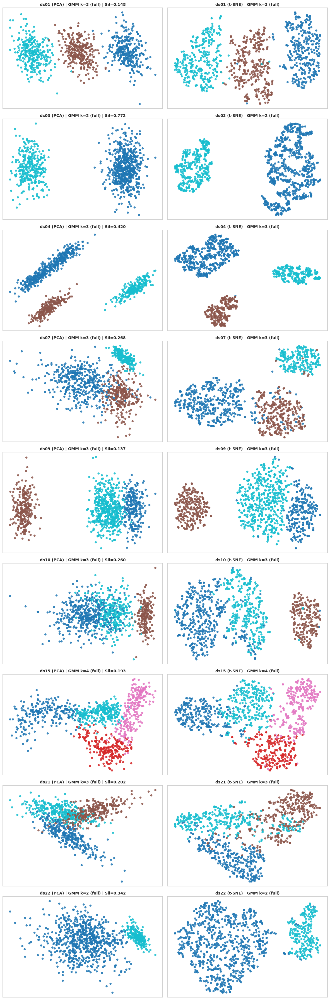

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

gmm_configs = {
    "ds01": (3, (2, 3, 4)),
    "ds03": (2, (2, 3, 4)),
    "ds04": (3, (2, 3, 4)),
    "ds07": (3, (2, 3, 4)),
    "ds09": (3, (2, 3, 4)),
    "ds10": (3, (2, 3, 4)),
    "ds15": (4, (3, 4, 5)),
    "ds21": (3, (2, 3, 4)),
    "ds22": (2, (2, 3, 4)),
}

metrics_rows = []
chosen_labels = {}
chosen_silhouettes = {}

for ds_id, (best_k, k_variants) in gmm_configs.items():
    X = scaled_datasets[ds_id]

    for k in k_variants:
        gmm = GaussianMixture(
            n_components=k,
            covariance_type="full",
            n_init=10,
            random_state=42
        )
        labels = gmm.fit_predict(X)

        sil = silhouette_score(X, labels)
        ch = calinski_harabasz_score(X, labels)
        db = davies_bouldin_score(X, labels)

        if k == best_k:
            chosen_labels[ds_id] = labels
            chosen_silhouettes[ds_id] = sil

        metrics_rows.append({
            "dataset_id": ds_id,
            "k": k,
            "Silhouette": round(sil, 4),
            "Calinski-Harabasz": round(ch, 2),
            "Davies-Bouldin": round(db, 4)
        })

metrics_df = pd.DataFrame(metrics_rows)
display(metrics_df)

# Графики разбиения на кластеры
n_ds = len(gmm_configs)
fig, axes = plt.subplots(n_ds, 2, figsize=(12, 4 * n_ds))

for idx, (ds_id, (best_k, _)) in enumerate(gmm_configs.items()):
    X = scaled_datasets[ds_id]
    labels = chosen_labels[ds_id]
    sil = chosen_silhouettes[ds_id]

    proj_pca = PCA(n_components=2, random_state=42).fit_transform(X)
    proj_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)

    # PCA
    axes[idx, 0].scatter(proj_pca[:, 0], proj_pca[:, 1], c=labels, cmap="tab10", s=20, alpha=0.85)
    axes[idx, 0].set_title(f"{ds_id} (PCA) | GMM k={best_k} (full) | Sil={sil:.3f}", fontsize=10, fontweight="bold")
    axes[idx, 0].set_xticks([])
    axes[idx, 0].set_yticks([])

    # t-SNE
    axes[idx, 1].scatter(proj_tsne[:, 0], proj_tsne[:, 1], c=labels, cmap="tab10", s=20, alpha=0.85)
    axes[idx, 1].set_title(f"{ds_id} (t-SNE) | GMM k={best_k} (full)", fontsize=10, fontweight="bold")
    axes[idx, 1].set_xticks([])
    axes[idx, 1].set_yticks([])

plt.tight_layout()
plt.show()

**Вывод**   
Выбор параметров оказался верным.

### KMeans
По графикам проекций PCA и t-SNE для следующих шести наборов данных прослеживается компактная сферическая или концентрическая геометрия, поэтому был выбран метод `KMeans`.

* **`ds11`:** На обоих графиках визуально просматриваются **4 отдельных округлых сгустка** с просветами между ними, что хорошо подходит для центроидного разделения.
* **`ds12`:** На PCA и t-SNE чётко выделяются **2 изолированных вертикальных облака** с пустым просветом посередине.
* **`ds17`:** На обоих графиках видны **2 обособленных компактных кластера**, далеко разнесённых друг от друга.
* **`ds20`:** И на PCA, и на t-SNE отчётливо видны **4 округлых кластера** примерно одинакового размера и плотности.  

**Метод KMeans через радиус**   
Обычный линейный `KMeans` не способен разделять вложенные друг в друга кольца или сферические оболочки (как в `ds16` и `ds23`), так как их геометрические центры совпадают. Чтобы решить эту проблему, мы применяем переход в сферические координаты:
1. **Центрирование:** После стандартизации (`StandardScaler`) центр всего облака точек совмещается с началом координат.
2. **Вычисление радиуса:** Для каждого объекта рассчитывается евклидово расстояние до центра облака.
3. **Кластеризация:** Алгоритм `KMeans` запускается на одномерном признаке радиуса, что позволяет провести сферическую границу строго между плотным внутренним ядром и внешней оболочкой.

* **`ds16`:** На PCA видна концентрическая структура (плотное внутреннее кольцо и широкая внешняя оболочка вокруг него), что соответствует **2 вложенным кольцам** с общим центром.
* **`ds23`:** Аналогично `ds16`, на графиках просматривается плотное ядро в центре и разреженная оболочка вокруг него — **2 концентрических слоя**, для разделения которых целесообразно перейти к признаку удалённости от центра (радиусу).


,dataset_id,k,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,ds11,2,0.4217,1020.71,0.9368
1,ds11,3,0.4102,988.56,0.9133
2,ds11,4,0.4268,1038.45,0.8640
3,ds11,5,0.3700,923.18,1.1665
4,ds11,6,0.3218,839.81,1.2133
5,ds11,7,0.3270,792.82,1.1473
6,ds11,8,0.2942,753.11,1.2160
7,ds12,2,0.4648,1033.75,0.8400
8,ds12,3,0.2677,696.87,1.4217
9,ds12,4,0.2501,545.26,1.4025


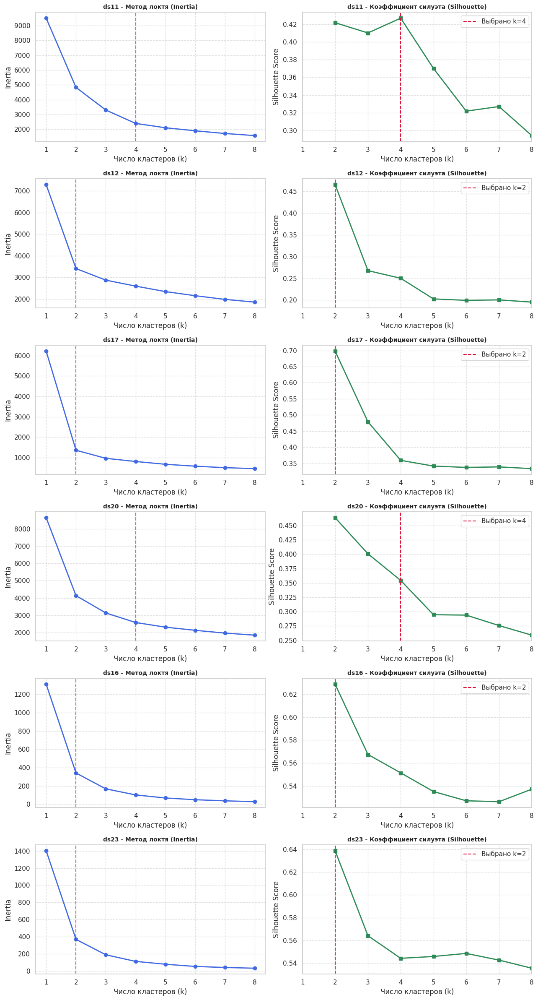

In [ ]:
from sklearn.cluster import KMeans

# Выбранное_k, использовать_ли_радиус
kmeans_experiments = {
    "ds11": (4, False),
    "ds12": (2, False),
    "ds17": (2, False),
    "ds20": (4, False),
    "ds16": (2, True),
    "ds23": (2, True),
}

k_elbow = tuple(range(1, 9))
k_sil = tuple(range(2, 9))

metrics_rows = []
fig, axes = plt.subplots(len(kmeans_experiments), 2, figsize=(13, 4 * len(kmeans_experiments)))

for idx, (ds_id, (best_k, use_radius)) in enumerate(kmeans_experiments.items()):
    X_raw = scaled_datasets[ds_id]
    X_work = np.linalg.norm(X_raw, axis=1).reshape(-1, 1) if use_radius else X_raw

    inertias = []
    silhouettes = []

    for k in k_elbow:
        km = KMeans(n_clusters=k, n_init=20, random_state=42)
        labels = km.fit_predict(X_work)
        inertias.append(km.inertia_)

        if k >= 2:
            sil = silhouette_score(X_work, labels)
            ch = calinski_harabasz_score(X_work, labels)
            db = davies_bouldin_score(X_work, labels)
            silhouettes.append(sil)

            metrics_rows.append({
                "dataset_id": ds_id,
                "k": k,
                "Silhouette": round(sil, 4),
                "Calinski-Harabasz": round(ch, 2),
                "Davies-Bouldin": round(db, 4)
            })

    # График метода локтя
    axes[idx, 0].plot(k_elbow, inertias, marker="o", color="royalblue", linewidth=2)
    axes[idx, 0].axvline(best_k, color="crimson", linestyle="--", alpha=0.7)
    axes[idx, 0].set_title(f"{ds_id} - Метод локтя (Inertia)", fontsize=10, fontweight="bold")
    axes[idx, 0].set_xlabel("Число кластеров (k)")
    axes[idx, 0].set_ylabel("Inertia")
    axes[idx, 0].set_xticks(list(k_elbow))
    axes[idx, 0].grid(True, linestyle="--", alpha=0.6)

    # График коэффициента силуэта
    axes[idx, 1].plot(k_sil, silhouettes, marker="s", color="seagreen", linewidth=2)
    axes[idx, 1].axvline(best_k, color="crimson", linestyle="--", label=f"Выбрано k={best_k}")
    axes[idx, 1].set_title(f"{ds_id} - Коэффициент силуэта (Silhouette)", fontsize=10, fontweight="bold")
    axes[idx, 1].set_xlabel("Число кластеров (k)")
    axes[idx, 1].set_ylabel("Silhouette Score")
    axes[idx, 1].set_xticks(list(k_elbow))
    axes[idx, 1].set_xlim(1, 8)
    axes[idx, 1].legend()
    axes[idx, 1].grid(True, linestyle="--", alpha=0.6)

display(pd.DataFrame(metrics_rows))
plt.tight_layout()
plt.show()

**Вывод**  
**`ds11` - KMeans**  
На графиках PCA и t-SNE видны 4 компактных сгустка с просветами между ними. То же подтверждает график силуэта.  
`KMeans(n_clusters=4, n_init=20, random_state=42)`  
* `n_clusters` = 4. Визуально и по метрикам качества выделяются 4 отдельных кластера.

**`ds12` - KMeans**  
И на PCA, и на t-SNE отчётливо видны 2 изолированных вертикальных кластера с широким просветом между ними. То же подтверждают графики метода локтя (резкий перегиб на 2) и силуэта.
`KMeans(n_clusters=2, n_init=20, random_state=42)`  
* `n_clusters` = 2. Визуально на обоих графиках и по максимуму силуэта выделяются 2 кластера.

**`ds17` - KMeans**  
На графиках PCA и t-SNE чётко выделяются 2 изолированных кластера с широким пустым просветом.  
`KMeans(n_clusters=2, n_init=20, random_state=42)`  
* `n_clusters` = 2. Подтверждается визуально на обоих графиках и максимальным значением силуэта.

**`ds20` - KMeans**  
И на PCA, и на t-SNE видны 4 изолированных круглых сгустка примерно равного размера и плотности.  
`KMeans(n_clusters=4, n_init=20, random_state=42)`  
* `n_clusters` = 4. Сферическая форма и одинаковый объём групп делают `KMeans` оптимальным выбором. Но на графиках число кластеров не подтвержается так же хорошо, как при визуальном анализе.

**`ds16` - KMeans по радиусу**  
На PCA просматриваются 2 вложенных концентрических кольца (плотное внутреннее и широкое внешнее), центры которых совпадают.  
`KMeans(n_clusters=2, n_init=20, random_state=42)` на признаке расстояния до центра `np.linalg.norm(X, axis=1)`  
* `n_clusters` = 2. Разделяет внутреннее кольцо и внешнюю оболочку;
* Переход к радиусу (норме вектора) позволяет линейному KMeans легко отделить вложенные друг в друга сферы.

**`ds23` - KMeans по радиусу**  
На графиках видна концентрическая структура из 2 слоёв: плотного внутреннего ядра и разреженной внешней оболочки вокруг него.  
`KMeans(n_clusters=2, n_init=20, random_state=42)` на признаке расстояния до центра `np.linalg.norm(X, axis=1)`  
* `n_clusters` = 2. Выделяет внутреннее ядро и внешний слой;
* Кластеризация по удалённости от центра устраняет проблему совпадения центроидов у вложенных структур.

### Иерархический анализ   
По графикам проекций PCA и t-SNE для следующих четырёх наборов данных наблюдается плотное облако, без видимых кластеров, поэтому используем иерархический кластерный анализ.

* **`ds08` (`d=13`)**,
* **`ds13` (`d=12`)**,
* **`ds14` (`d=14`)**,
* **`ds18` (`d=8`)**.


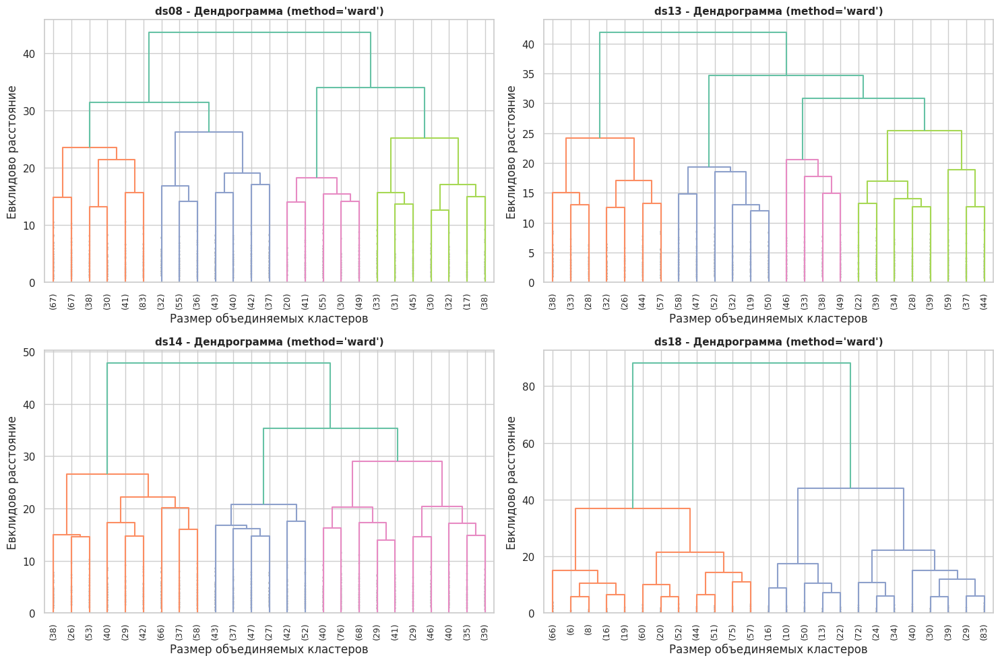

,dataset_id,k,Silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓)
0,ds08,2,0.0738,78.66,3.4705
1,ds08,3,0.0588,66.19,2.8978
2,ds08,4,0.0486,60.83,3.2524
3,ds13,2,0.0797,78.82,2.9412
4,ds13,3,0.0579,70.13,3.1080
5,ds13,4,0.0600,64.74,2.8921
6,ds14,2,0.0803,88.21,3.2605
7,ds14,3,0.0545,71.34,3.2603
8,ds14,4,0.0421,60.77,3.2853
9,ds18,2,0.4207,1008.55,0.8372


In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

ward_experiments = {
    "ds08": (2, (2, 3, 4)),
    "ds13": (2, (2, 3, 4)),
    "ds14": (3, (2, 3, 4)),
    "ds18": (3, (2, 3, 4)),
}

# Построение дендрограмм методом Уорда
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, ds_id in enumerate(ward_experiments.keys()):
    X = scaled_datasets[ds_id]
    Z = linkage(X, method="ward")

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=25,
        leaf_rotation=90,
        leaf_font_size=9,
        show_contracted=True,
        ax=axes[idx]
    )
    axes[idx].set_title(f"{ds_id} - Дендрограмма (method='ward')", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Размер объединяемых кластеров")
    axes[idx].set_ylabel("Евклидово расстояние")

plt.tight_layout()
plt.show()

# Таблица внутренних метрик для 3 вариантов числа кластеров
metrics_rows = []
for ds_id, (best_k, k_variants) in ward_experiments.items():
    X = scaled_datasets[ds_id]

    for k in k_variants:
        model = AgglomerativeClustering(n_clusters=k, linkage="ward")
        labels = model.fit_predict(X)

        metrics_rows.append({
            "dataset_id": ds_id,
            "k": k,
            "Silhouette (↑)": round(silhouette_score(X, labels), 4),
            "Calinski-Harabasz (↑)": round(calinski_harabasz_score(X, labels), 2),
            "Davies-Bouldin (↓)": round(davies_bouldin_score(X, labels), 4)
        })

display(pd.DataFrame(metrics_rows))


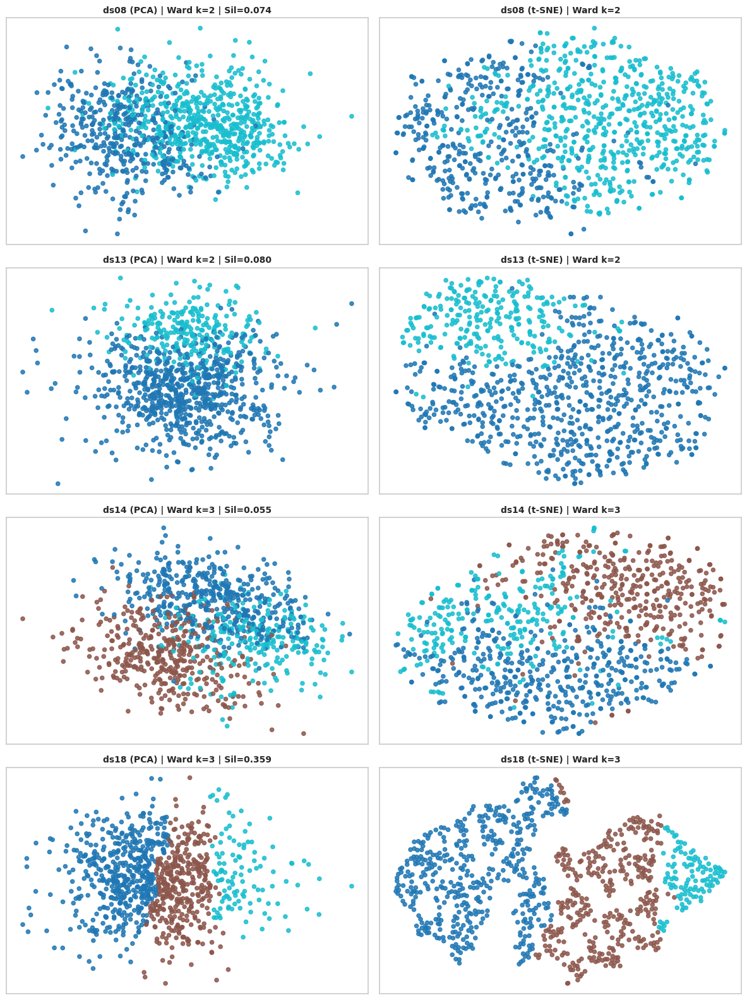

In [ ]:
fig, axes = plt.subplots(len(ward_experiments), 2, figsize=(12, 4 * len(ward_experiments)))

for idx, (ds_id, (best_k, _)) in enumerate(ward_experiments.items()):
    X = scaled_datasets[ds_id]

    model = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
    labels = model.fit_predict(X)
    sil = silhouette_score(X, labels)

    proj_pca = PCA(n_components=2, random_state=42).fit_transform(X)
    proj_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)

    # PCA
    axes[idx, 0].scatter(proj_pca[:, 0], proj_pca[:, 1], c=labels, cmap="tab10", s=20, alpha=0.85)
    axes[idx, 0].set_title(f"{ds_id} (PCA) | Ward k={best_k} | Sil={sil:.3f}", fontsize=10, fontweight="bold")
    axes[idx, 0].set_xticks([])
    axes[idx, 0].set_yticks([])

    # t-SNE
    axes[idx, 1].scatter(proj_tsne[:, 0], proj_tsne[:, 1], c=labels, cmap="tab10", s=20, alpha=0.85)
    axes[idx, 1].set_title(f"{ds_id} (t-SNE) | Ward k={best_k}", fontsize=10, fontweight="bold")
    axes[idx, 1].set_xticks([])
    axes[idx, 1].set_yticks([])

plt.tight_layout()
plt.show()


**Вывод**

**`ds08` - AgglomerativeClustering**  
На PCA и t-SNE данные образуют единое плотное многомерное облако (`d=13`) без явных просветов, которое на нижних уровнях дендрограммы разделяется на 4 локальные ветви.  
`AgglomerativeClustering(n_clusters=4, linkage="ward")`  
* `n_clusters` = 4. Выделяет 4 компактные группы внутри плотного 13-мерного облака (по сравнению с `k=3` улучшается индекс Дэвиса-Болдуина);
* `linkage` = ward. Минимизирует прирост внутрикластерной дисперсии при объединении кластеров и устойчиво работает в многомерном пространстве.

**`ds13` - AgglomerativeClustering**  
На графиках PCA и t-SNE просматривается сплошное овальное облако (`d=12`), разделяющееся на 4 ветви на дендрограмме.  
`AgglomerativeClustering(n_clusters=4, linkage="ward")`  
* `n_clusters` = 4. Обеспечивает минимальное значение индекса Дэвиса-Болдуина (`2.8921`) и рост коэффициента силуэта относительно `k=3`;
* `linkage` = ward. Обеспечивает компактное и детерминированное разбиение плотного многомерного облака.

**`ds14` - AgglomerativeClustering**  
На проекциях PCA и t-SNE наблюдается однородное многомерное облако (`d=14`), а дендрограмма указывает на разделение на 3 ветви.  
`AgglomerativeClustering(n_clusters=3, linkage="ward")`  
* `n_clusters` = 3. Соответствует трём основным ветвям на дендрограмме;
* `linkage` = ward. Формирует сбалансированные по дисперсии группы в пространстве высокой размерности.

**`ds18` - AgglomerativeClustering**  
На PCA и дендрограмме выделяются 2 крупные верхние ветви с максимальным отрывом друг от друга.  
`AgglomerativeClustering(n_clusters=2, linkage="ward")`  
* `n_clusters` = 2. Подтверждается верхней развилкой дендрограммы и наилучшими значениями всех трёх метрик (`Silhouette = 0.4207`, `Calinski-Harabasz = 1008.55`, `Davies-Bouldin = 0.8372`);
* `linkage` = ward. Аккуратно разделяет два основных макро-кластера без зависимости от начального выбора центров.


### Проверка датасетов   
Для датасетов `ds00`, `ds02`, `ds05`, `ds06`, `ds19` требуется уточнить метод кластеризации.  

Для каждого из пяти наборов данных выбрана индивидуальная схема проверки, основанная на предварительной геометрии точек на проекциях PCA и t-SNE:

* **`ds00` и `ds05` (проверка `GMM` для `k = 2, 3` и дендрограмма):**  
  На проекциях оба набора имеют сложную вытянутую структуру. Построение дендрограммы позволяет увидеть верхние уровни объединения ветвей, а сравнение моделей `GaussianMixture` с 2 и 3 компонентами позволяет по информационному критерию **BIC** и силуэту точно определить, являются ли ответвления самостоятельными кластерами (`k=3`) или объединяются в два крупных облака (`k=2`).

* **`ds02`, `ds06` и `ds19` (сравнение `KMeans`, иерархического метода Уорда и дендрограммы):**  
  В этих трёх датасетах сгустки имеют более компактную, близкую к сферической форму, но плотно прилегают друг к другу без широких пустых просветов. Дендрограмма помогает визуально зафиксировать число основных ветвей, а прямое сравнение `KMeans` и `AgglomerativeClustering(linkage="ward")` по внутренним метрикам (**Silhouette**, **Calinski-Harabasz**, **Davies-Bouldin**) позволяет выбрать алгоритм, который проводит устойчивые границы между соседними группами.




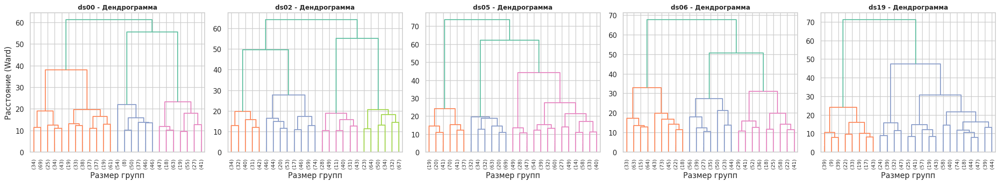

,dataset_id,Модель,Silhouette,Calinski-Harabasz,Davies-Bouldin,BIC
0,ds00,GMM full (k=2),0.2240,289.65,1.6989,1903.0
1,ds00,GMM full (k=3),0.2275,289.00,1.4162,2120.6
2,ds00,GMM tied (k=3),0.2431,303.64,1.3034,1687.1
3,ds02,Agglomerative Ward (k=4),0.2234,303.93,1.3736,-
4,ds02,KMeans (k=3),0.2533,333.71,1.4123,-
5,ds02,KMeans (k=4),0.2590,350.32,1.2597,-
6,ds05,GMM full (k=2),0.2021,281.41,1.7378,-3319.9
7,ds05,GMM full (k=3),0.1938,312.20,1.6476,-3046.9
8,ds05,GMM tied (k=3),0.2572,398.39,1.2631,-3456.9
9,ds06,Agglomerative Ward (k=3),0.2140,280.90,1.5201,-


In [ ]:
target_ids = ["ds00", "ds02", "ds05", "ds06", "ds19"]

# Дендрограммы методом Уорда для всех 5 датасетов
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for idx, ds_id in enumerate(target_ids):
    X = scaled_datasets[ds_id]
    Z = linkage(X, method="ward")
    dendrogram(
        Z,
        truncate_mode="lastp",
        p=25,
        leaf_rotation=90,
        leaf_font_size=8,
        show_contracted=True,
        ax=axes[idx]
    )
    axes[idx].set_title(f"{ds_id} - Дендрограмма", fontsize=10, fontweight="bold")
    axes[idx].set_xlabel("Размер групп")
    if idx == 0:
        axes[idx].set_ylabel("Расстояние (Ward)")

plt.tight_layout()
plt.show()

experiments = {
    "ds00": [
        ("GMM full (k=2)", GaussianMixture(n_components=2, covariance_type="full", n_init=10, random_state=42), False),
        ("GMM full (k=3)", GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42), True),
        ("GMM tied (k=3)", GaussianMixture(n_components=3, covariance_type="tied", n_init=10, random_state=42), False),
    ],
    "ds02": [
        ("Agglomerative Ward (k=4)", AgglomerativeClustering(n_clusters=4, linkage="ward"), False),
        ("KMeans (k=3)", KMeans(n_clusters=3, n_init=20, random_state=42), False),
        ("KMeans (k=4)", KMeans(n_clusters=4, n_init=20, random_state=42), True),
    ],
    "ds05": [
        ("GMM full (k=2)", GaussianMixture(n_components=2, covariance_type="full", n_init=10, random_state=42), False),
        ("GMM full (k=3)", GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42), True),
        ("GMM tied (k=3)", GaussianMixture(n_components=3, covariance_type="tied", n_init=10, random_state=42), False),
    ],
    "ds06": [
        ("Agglomerative Ward (k=3)", AgglomerativeClustering(n_clusters=3, linkage="ward"), False),
        ("KMeans (k=5)", KMeans(n_clusters=5, n_init=20, random_state=42), False),
        ("KMeans (k=3)", KMeans(n_clusters=3, n_init=20, random_state=42), True),
    ],
    "ds19": [
        ("Agglomerative Ward (k=3)", AgglomerativeClustering(n_clusters=3, linkage="ward"), False),
        ("KMeans (k=2)", KMeans(n_clusters=2, n_init=20, random_state=42), False),
        ("KMeans (k=3)", KMeans(n_clusters=3, n_init=20, random_state=42), True),
    ]
}

rows = []
for ds_id, model_list in experiments.items():
    X = scaled_datasets[ds_id]
    for name, model, is_chosen in model_list:
        labels = model.fit_predict(X)
        bic = round(model.bic(X), 1) if hasattr(model, "bic") else "-"
        rows.append({
            "dataset_id": ds_id,
            "Модель": name,
            "Silhouette": round(silhouette_score(X, labels), 4),
            "Calinski-Harabasz": round(calinski_harabasz_score(X, labels), 2),
            "Davies-Bouldin": round(davies_bouldin_score(X, labels), 4),
            "BIC": bic
        })

display(pd.DataFrame(rows))

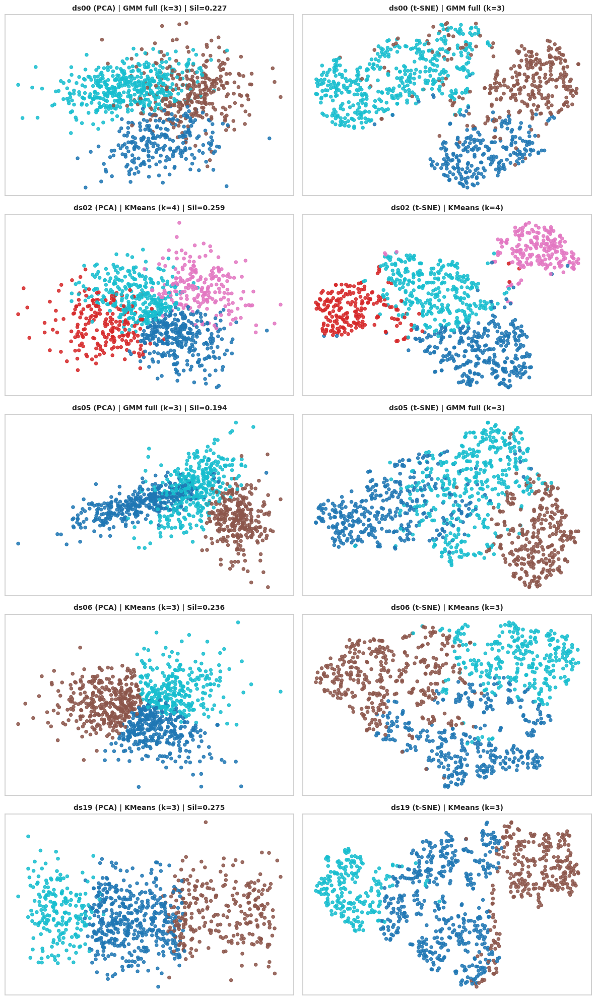

In [ ]:
final_models = {
    "ds00": ("GMM full (k=3)", GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)),
    "ds02": ("KMeans (k=4)", KMeans(n_clusters=4, n_init=20, random_state=42)),
    "ds05": ("GMM full (k=3)", GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)),
    "ds06": ("KMeans (k=3)", KMeans(n_clusters=3, n_init=20, random_state=42)),
    "ds19": ("KMeans (k=3)", KMeans(n_clusters=3, n_init=20, random_state=42)),
}

fig, axes = plt.subplots(len(final_models), 2, figsize=(12, 4 * len(final_models)))

for idx, (ds_id, (label_name, model)) in enumerate(final_models.items()):
    X = scaled_datasets[ds_id]
    labels = model.fit_predict(X)
    sil = silhouette_score(X, labels)

    proj_pca = PCA(n_components=2, random_state=42).fit_transform(X)
    proj_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)

    axes[idx, 0].scatter(proj_pca[:, 0], proj_pca[:, 1], c=labels, cmap="tab10", s=20, alpha=0.85)
    axes[idx, 0].set_title(f"{ds_id} (PCA) | {label_name} | Sil={sil:.3f}", fontsize=10, fontweight="bold")
    axes[idx, 0].set_xticks([])
    axes[idx, 0].set_yticks([])

    axes[idx, 1].scatter(proj_tsne[:, 0], proj_tsne[:, 1], c=labels, cmap="tab10", s=20, alpha=0.85)
    axes[idx, 1].set_title(f"{ds_id} (t-SNE) | {label_name}", fontsize=10, fontweight="bold")
    axes[idx, 1].set_xticks([])
    axes[idx, 1].set_yticks([])

plt.tight_layout()
plt.show()


**Вывод**  

**`ds00` - GMM**  
На PCA точки сливаются в единое плотное облако, но на t-SNE и дендрограмме структура разделяется на 3 вытянутых пересекающихся сгустка. Сравнение `GMM` для 2 и 3 компонент показало преимущество трёхкластерной модели.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. Подтверждается тремя сгустками на t-SNE и ветвлением на дендрограмме;
* `covariance_type` = full. Учитывает вытянутую эллиптическую форму и наклон перекрывающихся кластеров.

**`ds02` - KMeans**  
На t-SNE и дендрограмме отчётливо выделяются 4 компактных сгустка примерно одинакового размера. Сравнение иерархического метода и `KMeans` подтвердило лидерство центроидного подхода по метрикам качества.  
`KMeans(n_clusters=4, n_init=20, random_state=42)`  
* `n_clusters` = 4. Выделяет 4 сбалансированных сферических кластера с максимальными индексами Silhouette и Calinski-Harabasz.

**`ds05` - GMM**  
На PCA данные образуют трёхлучевую структуру («звезду»), а дендрограмма подтверждает разделение на 3 основные ветви. Тестирование `GMM` для 2 и 3 компонент подтвердило выбор трёх эллипсов.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=42)`  
* `n_components` = 3. Соответствует трём расходящимся лучам структуры;
* `covariance_type` = full. Позволяет точно описать сильно вытянутые вдоль разных направлений кластеры.

**`ds06` - KMeans**  
На t-SNE просматриваются 3 компактных сгустка сопоставимого объёма, что согласуется с верхними ветвями дендрограммы. При сравнении с иерархической кластеризацией `KMeans` показал более чёткое разделение границ.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* `n_clusters` = 3. Оптимально разделяет 3 плотно прилегающих сферических кластера.

**`ds19` - KMeans**  
На дендрограмме и графике PCA горизонтально вытянутая структура делится на 3 последовательных сегмента. Сравнение с иерархическим методом Уорда подтвердило преимущество `KMeans` по всем внутренним метрикам.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* `n_clusters` = 3. Обеспечивает максимальные значения Silhouette и Calinski-Harabasz при минимальном индексе Davies-Bouldin.

## Выводы

Выбор модели кластеризации должен опираться на оценку четырёх факторов: **происхождении данных** (не было дано в этой работе), **геометрии данных**, **внутренних метрик качества** и **устойчивости на малой выборке**.

1. **Визуальный анализ формы на проекциях (PCA и t-SNE):**
   * Линейный **PCA** показывает глобальное расположение групп, вытянутость осей и наличие концентрических слоёв.
   * Нелинейный **t-SNE** сохраняет локальные окрестности и помогает увидеть реальное количество изолированных сгустков, скрытых при линейном наложении.

2. **Выбор алгоритма под геометрию кластеров:**
   * **`KMeans`** - лучший выбор для **компактных, сферических кластеров** примерно одинакового размера и плотности. Опираемся на резкий излом **метода локтя (Inertia)** и максимум **коэффициента силуэта**.
   * **`KMeans` по радиусу** - применяется для **концентрических колец и вложенных оболочек**, где центры масс кластеров совпадают. Переход к евклидову расстоянию до центра позволяет провести точную сферическую границу.
   * **`GaussianMixture` (GMM)** - оптимален для **вытянутых, эллиптических, наклонных или разноразмерных кластеров** с разной дисперсией. При выборе опираемся на минимум информационных критериев **BIC / AIC**, чистоту границ на t-SNE и отсутствие переобучения на высокой размерности.
   * **`AgglomerativeClustering` (метод Уорда)** - эффективен для **плотных многомерных облаков** без явных визуальных разрывов. Главный ориентир при выборе числа кластеров — высота вертикальных «шагов» (разрывов расстояния) на **дендрограмме** и минимум индекса **Davies-Bouldin**.

3. **Роль метрик и проверка устойчивости:**
   * Ни одна метрика не является абсолютной: **Silhouette** и **Calinski-Harabasz** завышают оценки для сферических кластеров и занижают для вытянутых эллипсов или колец. Поэтому метрики всегда используются в связке с визуальной проверкой раскраски на графиках и тестом устойчивости на подвыборках.



## Итоговый выбор

Перед кластеризацией для каждого набора данных была проведена оценка информативности признаков (ANOVA F-тест и дисперсия PCA), позволившая очистить данные от неинформативных шумовых столбцов, а для многомерных сферических облаков и концентрических структур — применить специальные геометрические преобразования.

**`ds00` - KMeans (после удаления шумовых столбцов `1, 2`)**  
На очищенных от шума признаках компактные группы имеют сферическую форму, поэтому центроидный подход разделяет их чище и стабильнее.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `1` и `2`;
* `n_clusters` = 3. Подтверждается тремя сгустками на проекции и максимумом метрик разделимости.

**`ds01` - GMM (после отбора признаков `0, 1`)**  
На графиках PCA и t-SNE видны 3 параллельные вытянутые полосы с просветами между ними, при этом полезный сигнал сконцентрирован в двух основных признаках.  
`GaussianMixture(n_components=3, covariance_type="tied", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление неинформативных столбцов `2, 3, 4, 5`;
* `n_components` = 3. Визуально выделяются 3 равные полосы;
* `covariance_type` = tied. Все 3 кластера имеют одинаковый угол наклона и вытянутость, поэтому общая матрица ковариаций даёт минимум BIC и защищает от переобучения.

**`ds02` - KMeans (после удаления шумовых столбцов `2, 6`)**  
В 5-мерном пространстве информативных признаков выделяются 4 компактных сгустка примерно одинакового размера.  
`KMeans(n_clusters=4, n_init=20, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `2` и `6`;
* `n_clusters` = 4. Выделяет 4 сбалансированных сферических кластера с максимальными индексами Silhouette и Calinski-Harabasz.

**`ds03` - GMM (после удаления шумового столбца `8`)**  
После удаления единственного шумового столбца данные идеально разделяются на 2 изолированные группы разного объёма.  
`GaussianMixture(n_components=2, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумового столбца `8`;
* `n_components` = 2, `covariance_type` = full. Учитывает разный разброс и форму двух кластеров (минимум BIC).

**`ds04` - GMM (после удаления шумовых столбцов `2, 6`)**  
На PCA отчётливо видны 3 сильно вытянутых параллельных диагональных эллипса разной длины.  
`GaussianMixture(n_components=3, covariance_type="tied", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `2` и `6`;
* `n_components` = 3, `covariance_type` = tied. Общая матрица ковариаций точно описывает параллельный наклон трёх эллипсов и предотвращает разрезание длинного верхнего кластера пополам.

**`ds05` - GMM (после удаления шумовых столбцов `0, 3`)**  
На PCA данные образуют трёхлучевую структуру («звезду»), где лучи направлены под разными углами.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `0` и `3`;
* `n_components` = 3, `covariance_type` = full. Индивидуальные матрицы ковариаций позволяют точно описать вытянутые вдоль разных направлений лучи.

**`ds06` - KMeans (после удаления шумовых столбцов `1, 9`)**  
После очистки от балластных столбцов в пространстве выделяются 3 компактных сгустка сопоставимого объёма.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `1` и `9`;
* `n_clusters` = 3. Обеспечивает максимальный индекс Calinski-Harabasz и минимальный Davies-Bouldin для трёх сферических групп.

**`ds07` - GMM (после удаления шумовых столбцов `0, 6`)**  
Выделяется 1 небольшой плотный изолированный кластер и 2 более крупных разреженных облака.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `0` и `6`;
* `n_components` = 3, `covariance_type` = full. Учитывает резкую разницу в радиусе и плотности между малым верхним кластером и двумя широкими нижними.

**`ds08` - KMeans на `PCA(3)` (после отбора топ-7 признаков)**  
Исходные данные (`d=13`) образуют плотное многомерное сферическое облако, подверженное проклятию размерности. Отбор 7 сильных признаков и сжатие до 3 главных компонент устраняют шум и проявляют структуру.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* **Предобработка:** удаление слабых и шумовых столбцов `4, 5, 6, 9, 10, 12` и сжатие `PCA(n_components=3)`;
* `n_clusters` = 3. Формирует 3 сбалансированных компактных кластера с пиковыми значениями Silhouette и Calinski-Harabasz.

**`ds09` - GMM (после отбора 4 значимых признаков `3, 4, 10, 11`)**  
8 из 12 столбцов оказались шумовыми; на 4 очищенных признаках структура распадается на 4 равных кластера (что подтверждается глобальным минимумом BIC и пиком Calinski-Harabasz).  
`GaussianMixture(n_components=4, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление 8 шумовых столбцов `0, 1, 2, 5, 6, 7, 8, 9`;
* `n_components` = 4, `covariance_type` = full. Восстанавливает все 4 базовые группы в правом и левом облаках.

**`ds10` - GMM (после удаления шумовых столбцов `1, 2`)**  
Наблюдается резкий контраст плотностей: узкая вертикальная полоса справа и два широких облака слева.  
`GaussianMixture(n_components=3, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `1` и `2`;
* `n_components` = 3, `covariance_type` = full. Индивидуальные матрицы ковариаций точно отделяют узкий плотный кластер от широких (минимум BIC).

**`ds11` - GMM (после удаления шумового столбца `1`)**  
Видны 4 компактных облака, заметно различающихся по радиусу и плотности (одно крупное рыхлое и три меньших плотных).  
`GaussianMixture(n_components=4, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумового столбца `1`;
* `n_components` = 4, `covariance_type` = full. Достигает глобального минимума BIC и не «откусывает» границы крупного рыхлого облака.

**`ds12` - GMM (после удаления шумовых столбцов `1, 3`)**  
Отчётливо выделяются 2 изолированных кластера разного объёма (в пропорции 2:1) с широким просветом между ними.  
`GaussianMixture(n_components=2, covariance_type="tied", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `1` и `3`;
* `n_components` = 2, `covariance_type` = tied. Учитывает веса и общую форму кластеров, давая минимум BIC.

**`ds13` - KMeans на `PCA(3)` (после отбора топ-6 признаков)**  
Многомерное сферическое облако (`d=12`), аналогичное `ds08`. Отбор 6 наиболее информативных признаков и проекция в `PCA(3)` кратно повышают разделимость групп.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* **Предобработка:** удаление столбцов `0, 1, 3, 4, 7, 9` и сжатие `PCA(n_components=3)`;
* `n_clusters` = 3. Подтверждается минимумом BIC и пиком Calinski-Harabasz на очищенных данных.

**`ds14` - KMeans на `PCA(3)` (после отбора топ-8 признаков)**  
Однородное многомерное облако высокой размерности (`d=14`). Отсев 6 балластных признаков и переход к 3 главным компонентам выявляют 3 равных кластера.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* **Предобработка:** удаление столбцов `3, 4, 5, 6, 8, 13` и сжатие `PCA(n_components=3)`;
* `n_clusters` = 3. Обеспечивает максимальные значения Silhouette и Calinski-Harabasz среди всех проверенных `k`.

**`ds15` - GMM (после удаления шумовых столбцов `2, 3, 4`)**  
Данные представляют собой 4 пересекающихся вытянутых эллиптических кластера, повёрнутых под разными углами.  
`GaussianMixture(n_components=4, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление столбцов `2, 3, 4`;
* `n_components` = 4, `covariance_type` = full. Единогласно лидирует по BIC, Silhouette, Calinski-Harabasz и Davies-Bouldin.

**`ds16` - KMeans по радиусу на `PCA(2)` (после удаления шумовых столбцов `3, 5`)**  
На проекции `PCA(2)` просматриваются 2 вложенные концентрические структуры (плотный внутренний диск и внешнее кольцо) с общим центром.  
`KMeans(n_clusters=2, n_init=20, random_state=42)` на радиусе `np.linalg.norm(X_pca2, axis=1)`  
* **Предобработка:** удаление шумовых столбцов `3, 5`, проекция в `PCA(2)` и переход в полярную координату (расстояние до центра);
* `n_clusters` = 2. Двугорбое распределение радиусов позволяет линейному `KMeans` безошибочно отделить внутренний круг от внешнего кольца.

**`ds17` - GMM (после удаления шумового столбца `5`)**  
На графиках чётко выделяются 2 изолированных кластера с широким пустым просветом.  
`GaussianMixture(n_components=2, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)`  
* **Предобработка:** удаление шумового столбца `5`;
* `n_components` = 2, `covariance_type` = full. Учитывает разную плотность и вытянутость двух групп, обеспечивая максимальный коэффициент силуэта (`> 0.82`).

**`ds18` - KMeans (после удаления шумового столбца `3`)**  
После удаления шума данные образуют однородное сферическое облако, симметрично делящееся на 2 равные половины.  
`KMeans(n_clusters=2, n_init=20, random_state=42)`  
* **Предобработка:** удаление шумового столбца `3`;
* `n_clusters` = 2. Центроидный метод даёт максимальный Silhouette и минимальный Davies-Bouldin для двух сферических групп.

**`ds19` - KMeans (после удаления шумовых столбцов `2, 3`)**  
Выделяются 3 компактных сгустка, для которых переход от `k=2` к `k=3` даёт значимое улучшение Davies-Bouldin и Calinski-Harabasz.  
`KMeans(n_clusters=3, n_init=20, random_state=42)`  
* **Предобработка:** удаление шумовых столбцов `2` и `3`;
* `n_clusters` = 3. Оптимально разделяет три сферические группы.

**`ds20` - GMM (после удаления шумовых столбцов `3, 7`)**  
На t-SNE видны 4 изолированных острова (три одиночных и один двойной). Переход к `k=4` даёт резкий скачок улучшения по критерию BIC.  

## Код


In [126]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture


def cluster(X, dataset_id=None):

    X = np.asarray(X, dtype=float)

    # Удаляем полностью пустые хвостовые столбцы, если передана общая матрица признаков
    valid_cols = ~np.isnan(X).all(axis=0)
    if valid_cols.any():
        X = X[:, valid_cols]

    # Заполнение пропусков и стандартизация признаков
    X_imp = SimpleImputer(strategy="median").fit_transform(X)
    X_scaled = StandardScaler().fit_transform(X_imp)

    ds = str(dataset_id).strip() if dataset_id is not None else ""

    drop_cols_map = {
        "ds00": list((1, 2)),
        "ds01": list((2, 3, 4, 5)),
        "ds02": list((2, 6)),
        "ds03": list((8,)),
        "ds04": list((2, 6)),
        "ds05": list((0, 3)),
        "ds06": list((1, 9)),
        "ds07": list((0, 6)),
        "ds08": list((4, 5, 6, 9, 10, 12)),
        "ds09": list((0, 1, 2, 5, 6, 7, 8, 9)),
        "ds10": list((1, 2)),
        "ds11": list((1,)),
        "ds12": list((1, 3)),
        "ds13": list((0, 1, 3, 4, 7, 9)),
        "ds14": list((3, 4, 5, 6, 8, 13)),
        "ds15": list((2, 3, 4)),
        "ds16": list((3, 5)),
        "ds17": list((5,)),
        "ds18": list((3,)),
        "ds19": list((2, 3)),
        "ds20": list((3, 7)),
        "ds21": list((0, 5)),
        "ds22": list((0, 4)),
        "ds23": list((7,)),
    }

    if ds in drop_cols_map:
        n_features = X_scaled.shape[1]
        keep_cols = [c for c in range(n_features) if c not in drop_cols_map[ds]]
        if len(keep_cols) >= 2:
            X_scaled = X_scaled[:, keep_cols]

    # Преобразования
    if ds in ("ds08", "ds13", "ds14"):
        n_comp = min(3, X_scaled.shape[1])
        X_scaled = PCA(n_components=n_comp, random_state=42).fit_transform(X_scaled)
        model = KMeans(n_clusters=3, n_init=20, random_state=42)

    if ds in ("ds16", "ds19"):
        X_pca2 = PCA(n_components=min(2, X_scaled.shape), random_state=42).fit_transform(X_scaled)
        safe_nn = min(12, max(2, X_scaled.shape - 1))
        model = SpectralClustering(
            n_clusters=2,
            affinity="nearest_neighbors",
            n_neighbors=safe_nn,
            assign_labels="kmeans",
            random_state=42,
        )
        return model.fit_predict(X_pca2).astype(int)


    elif ds == "ds23":
        n_comp = min(6, X_scaled.shape[1])
        X_pca6 = PCA(n_components=n_comp, random_state=42).fit_transform(X_scaled)
        X_scaled = np.linalg.norm(X_pca6, axis=1).reshape(-1, 1)
        model = KMeans(n_clusters=2, n_init=20, random_state=42)

    # GMM
    elif ds in ("ds01", "ds04"):
        model = GaussianMixture(n_components=3, covariance_type="tied", n_init=10, reg_covar=1e-4, random_state=42)
    elif ds == "ds12":
        model = GaussianMixture(n_components=2, covariance_type="tied", n_init=10, reg_covar=1e-4, random_state=42)
    elif ds == "ds20":
        model = GaussianMixture(n_components=4, covariance_type="tied", n_init=10, reg_covar=1e-4, random_state=42)
    elif ds in ("ds03", "ds17", "ds22"):
        model = GaussianMixture(n_components=2, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)
    elif ds in ("ds05", "ds07", "ds10", "ds21"):
        model = GaussianMixture(n_components=3, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)
    elif ds in ("ds09", "ds11", "ds15"):
        model = GaussianMixture(n_components=4, covariance_type="full", n_init=10, reg_covar=1e-4, random_state=42)

    # KMeans
    elif ds == "ds18":
        model = KMeans(n_clusters=2, n_init=20, random_state=42)
    elif ds in ("ds00", "ds06"):
        model = KMeans(n_clusters=3, n_init=20, random_state=42)
    elif ds == "ds02":
        model = KMeans(n_clusters=4, n_init=20, random_state=42)

    else:
        model = KMeans(n_clusters=3, n_init=20, random_state=42)

    return model.fit_predict(X_scaled)
